# KC House - Regressão Linear

In [1]:
%pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Importando as Bibliotecas

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Carregamento dos dados do CSV

In [68]:
try:
    dados = np.loadtxt('kc_house_data.csv', delimiter=',', skiprows=1, usecols=(19, 2))
    #dados = np.getFromTxt('kc_house_data.csv', delimiter=',', skip_header=1, usecols=(5, 2))
except FileNotFoundError:
    print("Erro: Arquivo 'kc_house_data.csv' não encontrado")
    print("Por favor, crie o arquivo ou execute o script para gerá-lo")
    exit()

print(dados)

[[  1340. 221900.]
 [  1690. 538000.]
 [  2720. 180000.]
 ...
 [  1020. 402101.]
 [  1410. 400000.]
 [  1020. 325000.]]


## Separando de dados de X e Y

In [69]:
x = dados[:,0]
y = dados[:,1]

print(x)
print(y)

print(f"\nNúmero de Amostras: {len(x)}")

[1340. 1690. 2720. ... 1020. 1410. 1020.]
[221900. 538000. 180000. ... 402101. 400000. 325000.]

Número de Amostras: 21613


In [70]:
x = x.reshape(-1,1)
y = y.reshape(-1,1)

print("X: ",x)
print("y: ",y)

X:  [[1340.]
 [1690.]
 [2720.]
 ...
 [1020.]
 [1410.]
 [1020.]]
y:  [[221900.]
 [538000.]
 [180000.]
 ...
 [402101.]
 [400000.]
 [325000.]]


## Caalculando "a" e "b"

In [71]:
x_mean = np.mean(x)
y_mean = np.mean(y)

print("Media de X",x_mean)
print("media de y", y_mean)

Media de X 1986.552491556008
media de y 540088.1417665294


## DF Predict

In [72]:
def predict(X_novo,_m,_b):
    return _m * X_novo + _b

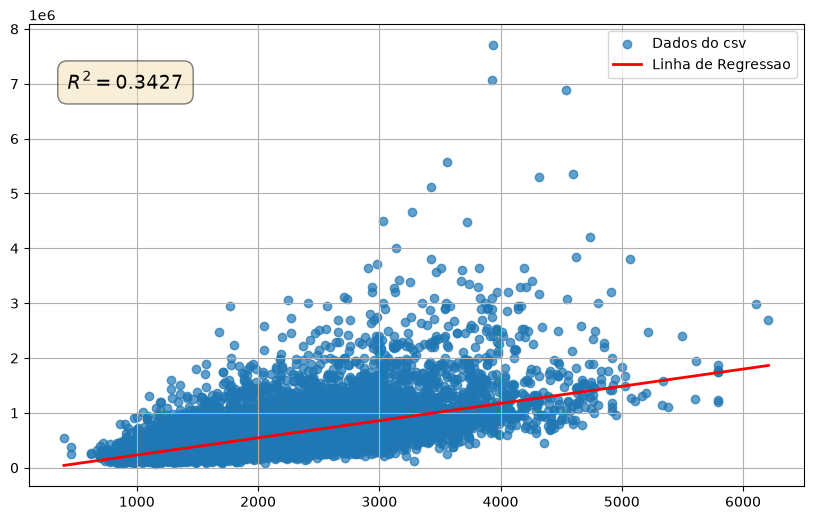

In [73]:
n = len(x)
numerador = np.sum((x - x_mean) * (y - y_mean))
denominador = np.sum((x - x_mean)**2)

m = numerador / denominador
b = y_mean - (m * x_mean)

y_pred = m * x + b

sqr = np.sum((y - y_pred)**2)
sqt = np.sum((y - y_mean)**2)

r2 = 1 - (sqr / sqt)

if r2 > 0.75:
    print("O modelo tem um bom ajuste de dados")
elif r2 > 0.5:
    print("O modelo tem um ajuste moderado")

x_line = np.array([x.min(), x.max()])
y_line = m * x_line + b

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='Dados do csv', alpha=0.7)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Linha de Regressao')

# Correções aplicadas aqui (transform e .4f)
plt.text(0.05, 0.9, f'$R^2 = {r2:.4f}$', transform=plt.gca().transAxes, 
         fontsize=14, verticalalignment='top', 
         bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

plt.legend()
plt.grid(True)
plt.show()